In [1]:
# ruff: noqa: F405
from pathlib import Path
from pickle import dump, load
from typing import Iterable

import anndata as ad
import numpy as np
import scanpy as sc
from plotnine import *  # noqa: F403
from shared import psc_ds, run_nmf, run_proc_per_ds, viz_defs

import apl
import spatialpeeler as sP
from spatialpeeler.diag import comp_sparsity, sweep_uns

viz_defs()
RAND_SEED = 28

In [2]:
# load dataset + run NMF
if (pth := Path("../.cache/psc.pkl")).exists():
    with open(pth, "rb") as f:
        psc = load(f)
else:
    adatas = psc_ds(
        Path("../data/psc-visium"),
    )
    for k in adatas:
        adatas[k] = adatas[k][adatas[k].obs["in_tissue"], :]

    run_proc_per_ds(adatas)

    psc = ad.concat(adatas, label="sample_id", index_unique="_")
    sc.pp.filter_genes(psc, min_cells=psc.n_obs // 500)

    run_nmf(psc, 30, RAND_SEED)

    pth.parent.mkdir(exist_ok=True)
    with open(pth, "wb") as f:
        dump(psc, f)
print(psc)

AnnData object with n_obs × n_vars = 21553 × 16465
    obs: 'in_tissue', 'percent.mt', 'cell_type', 'group', 'sample_id'
    var: 'n_cells'
    obsm: 'spatial', 'X_nmf'
    varm: 'X_nmf'
    layers: 'counts'


with our processed data, we proceed with the factor-wise regression step of spatialPeeler

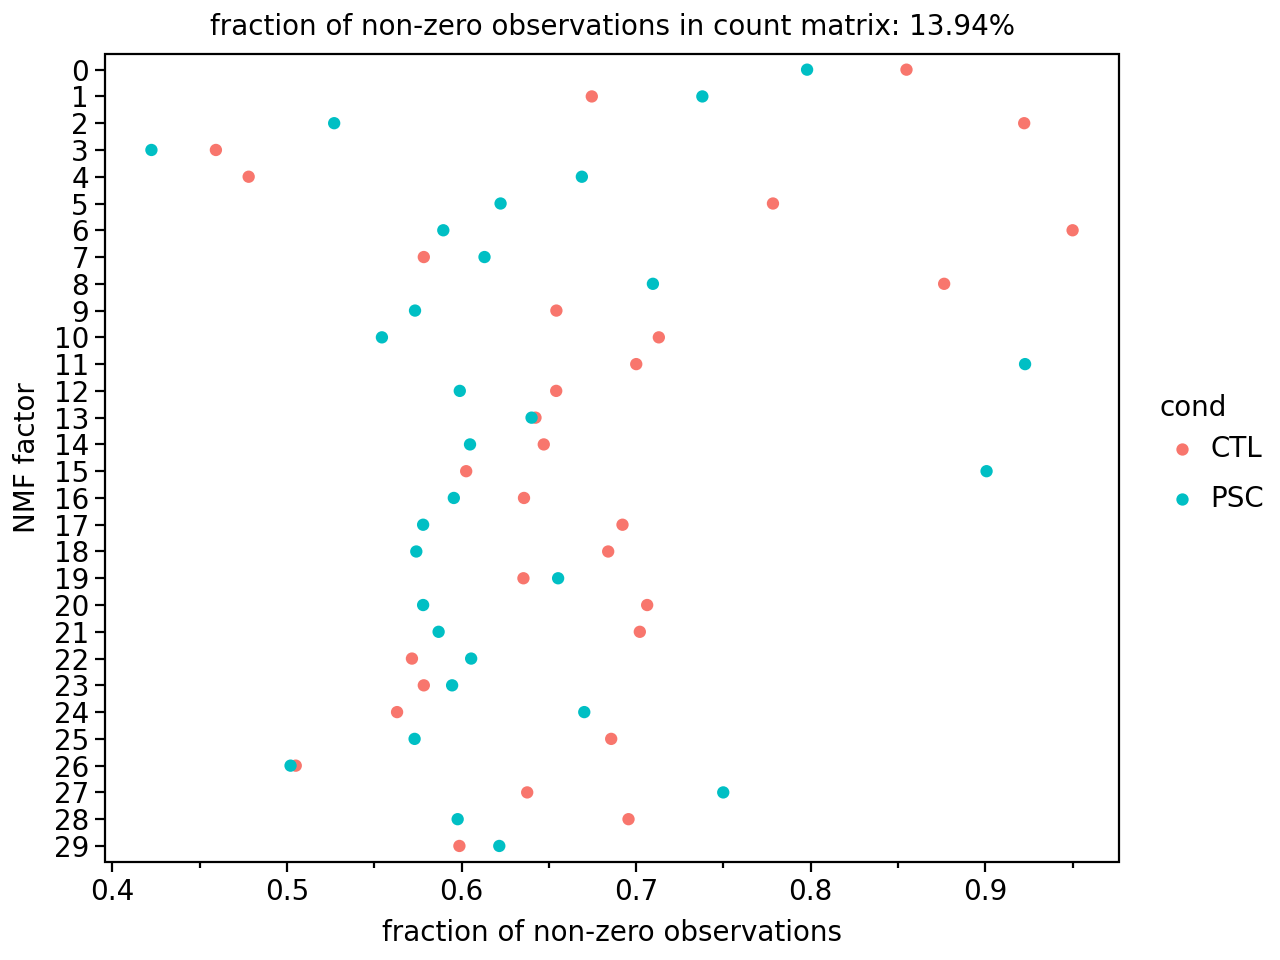

In [3]:
X_spars = psc.X.nnz / np.prod(psc.X.shape)  # ty:ignore[unresolved-attribute]
(
    comp_sparsity(psc.obsm["X_nmf"], cond=psc.obs["group"])
    >> ggplot()
    + aes(x="density", y="column", color="cond")
    + geom_point()
    + scale_y_discrete(limits=reversed)  # ty:ignore[invalid-argument-type]
    + labs(
        x="fraction of non-zero observations",
        y="NMF factor",
        title=f"fraction of non-zero observations in count matrix: {X_spars * 100:.02f}%",
    )
).show()

In [4]:
# run factor-wise regression step
for k in range(psc.obsm["X_nmf"].shape[1]):
    sP.run_fact_reg(psc, "group", "CTL", k, f"sP_p_hat_k={k:02}", X_key="X_nmf")

print(psc)

AnnData object with n_obs × n_vars = 21553 × 16465
    obs: 'in_tissue', 'percent.mt', 'cell_type', 'group', 'sample_id'
    var: 'n_cells'
    uns: 'sP_p_hat_k=00', 'sP_p_hat_k=01', 'sP_p_hat_k=02', 'sP_p_hat_k=03', 'sP_p_hat_k=04', 'sP_p_hat_k=05', 'sP_p_hat_k=06', 'sP_p_hat_k=07', 'sP_p_hat_k=08', 'sP_p_hat_k=09', 'sP_p_hat_k=10', 'sP_p_hat_k=11', 'sP_p_hat_k=12', 'sP_p_hat_k=13', 'sP_p_hat_k=14', 'sP_p_hat_k=15', 'sP_p_hat_k=16', 'sP_p_hat_k=17', 'sP_p_hat_k=18', 'sP_p_hat_k=19', 'sP_p_hat_k=20', 'sP_p_hat_k=21', 'sP_p_hat_k=22', 'sP_p_hat_k=23', 'sP_p_hat_k=24', 'sP_p_hat_k=25', 'sP_p_hat_k=26', 'sP_p_hat_k=27', 'sP_p_hat_k=28', 'sP_p_hat_k=29'
    obsm: 'spatial', 'X_nmf', 'sP_p_hat_k=00', 'sP_p_hat_k=01', 'sP_p_hat_k=02', 'sP_p_hat_k=03', 'sP_p_hat_k=04', 'sP_p_hat_k=05', 'sP_p_hat_k=06', 'sP_p_hat_k=07', 'sP_p_hat_k=08', 'sP_p_hat_k=09', 'sP_p_hat_k=10', 'sP_p_hat_k=11', 'sP_p_hat_k=12', 'sP_p_hat_k=13', 'sP_p_hat_k=14', 'sP_p_hat_k=15', 'sP_p_hat_k=16', 'sP_p_hat_k=17', 'sP_p_

we now assess our resulting regression outputs distributions \
we can extract and collate the model betas and other statistics using the sweep_uns function

/workspaces/.venv/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log


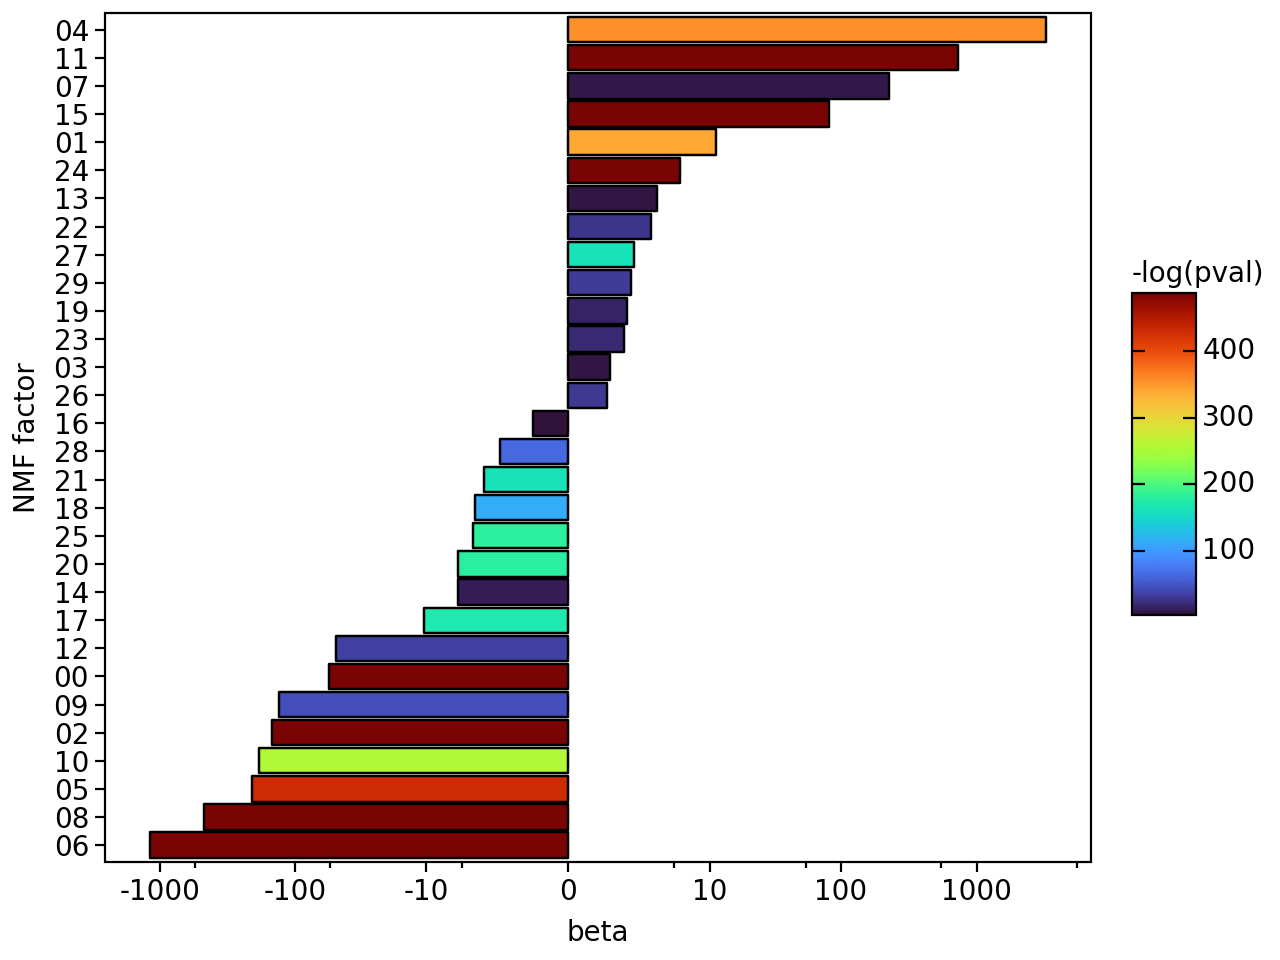

In [5]:
(
    sweep_uns(psc, "sP_p_hat_k={k}")
    >> ggplot()
    + aes(x="reorder(k, beta)", fill="-np.log(pval)", y="beta")
    + geom_col(color="black")
    + coord_flip()
    + labs(fill="-log(pval)", x="NMF factor")
    + scale_fill_cmap("turbo")
    + scale_y_symlog()
).show()

In [6]:
def pl_k_sp(adata: ad.AnnData, k_oi: int) -> Iterable[ggplot]:
    obsm_sl_oi = f"sP_p_hat_k={k_oi:02}"

    plo = apl.PlotAdata(adata)

    return [
        (
            plo
            + aes(color=apl.obsm(obsm_sl_oi, sP.PAT_KEY))
            + scale_color_cmap("cividis")
            + coord_fixed()
            + aes(x=apl.obsm("spatial", "x"), y=apl.obsm("spatial", "y"))
            + geom_point(shape="h", size=0.1)
            + facet_wrap([apl.obs("group"), apl.obs("sample_id")], nrow=2, shrink=False, scales="free")
            + labs(color="p\u0302", title=f"p\u0302 spatial distributions for k={k_oi}")
            + theme(axis_text=element_blank(), axis_ticks=element_blank())
        ),
        (
            plo
            + aes(
                x=apl.obsm("X_nmf", k_oi),
                y=apl.obsm(obsm_sl_oi, sP.PAT_KEY),
                color=apl.obs("group"),
            )
            + geom_point(alpha=1)
            + facet_wrap(apl.obs("group"))
            + scale_x_continuous(expand=(0.1, 0))
            + labs(y="p\u0302", title=f"p\u0302 / NMF for k={k_oi}")
        ),
        (
            plo
            + aes(
                x=apl.obs("sample_id"),
                y=apl.obsm(obsm_sl_oi, sP.PAT_KEY),
                fill=stage(apl.obsm(obsm_sl_oi, sP.BIN_KEY), "np.where(fill, '1', '0')"),
            )
            + geom_violin(scale="count")
            + geom_boxplot(width=0.1, outlier_shape="", position=position_dodge(0.9), show_legend=False)
            + labs(y="p\u0302", title=f"p\u0302 distributions for k={k_oi}", fill="")
            + geom_hline(
                yintercept=adata.obsm[obsm_sl_oi]
                .groupby(sP.BIN_KEY)[sP.PAT_KEY]  # ty:ignore[unresolved-attribute]
                .agg(["min", "max"])
                .melt()["value"]
                .iloc[[1, 2]]
                .mean(),
                linetype="dashed",
                alpha=0.8,
                color="red",
            )
            + coord_flip()
            + scale_x_discrete(limits=reversed)  # ty:ignore[invalid-argument-type]
            + guides(color="none")
        ),
    ]

we can see that factor 4 has a strong case-specific profile \
we plot its (and associated p_hat) distributions below:

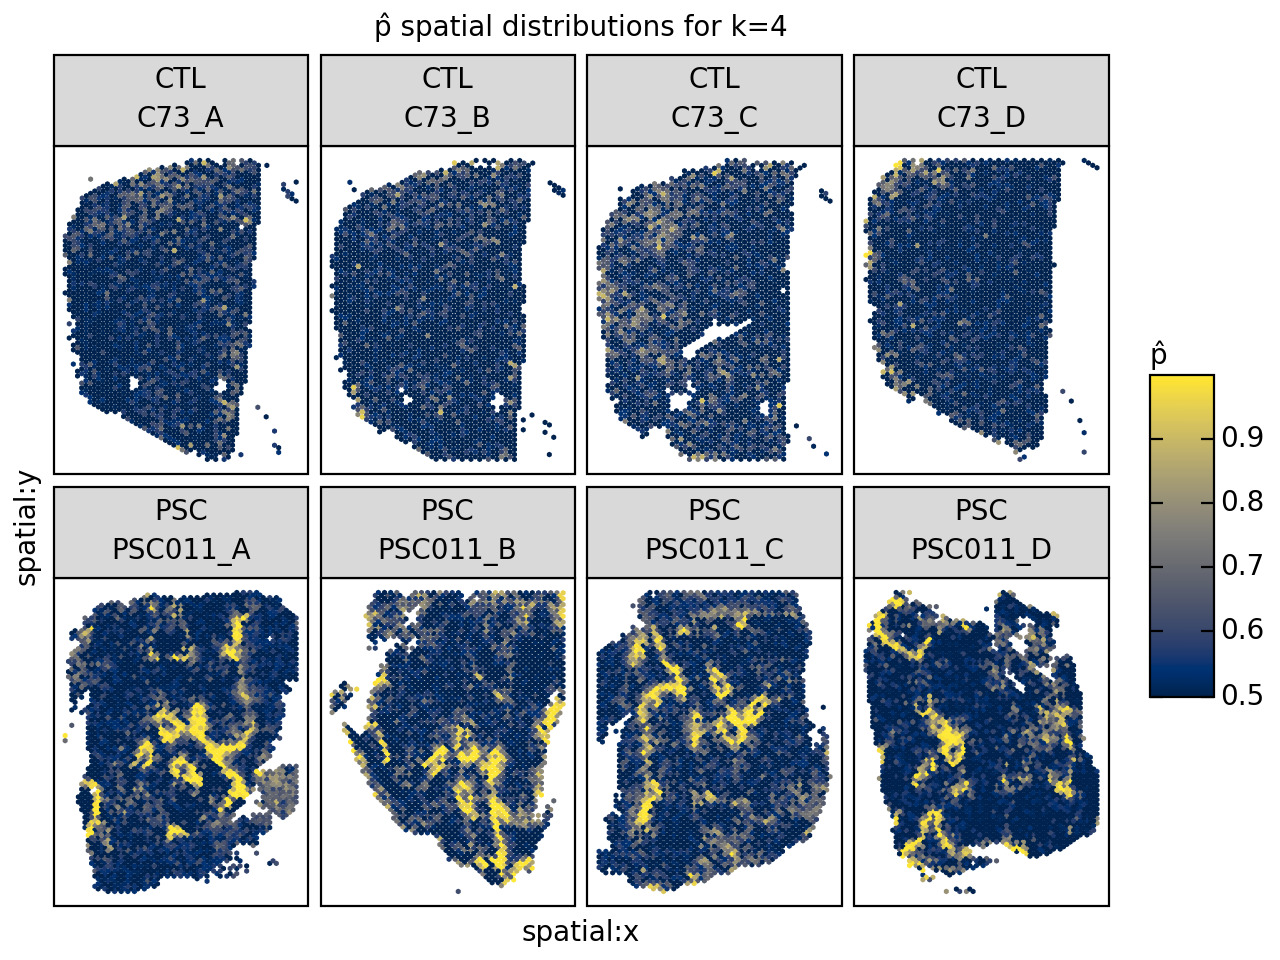

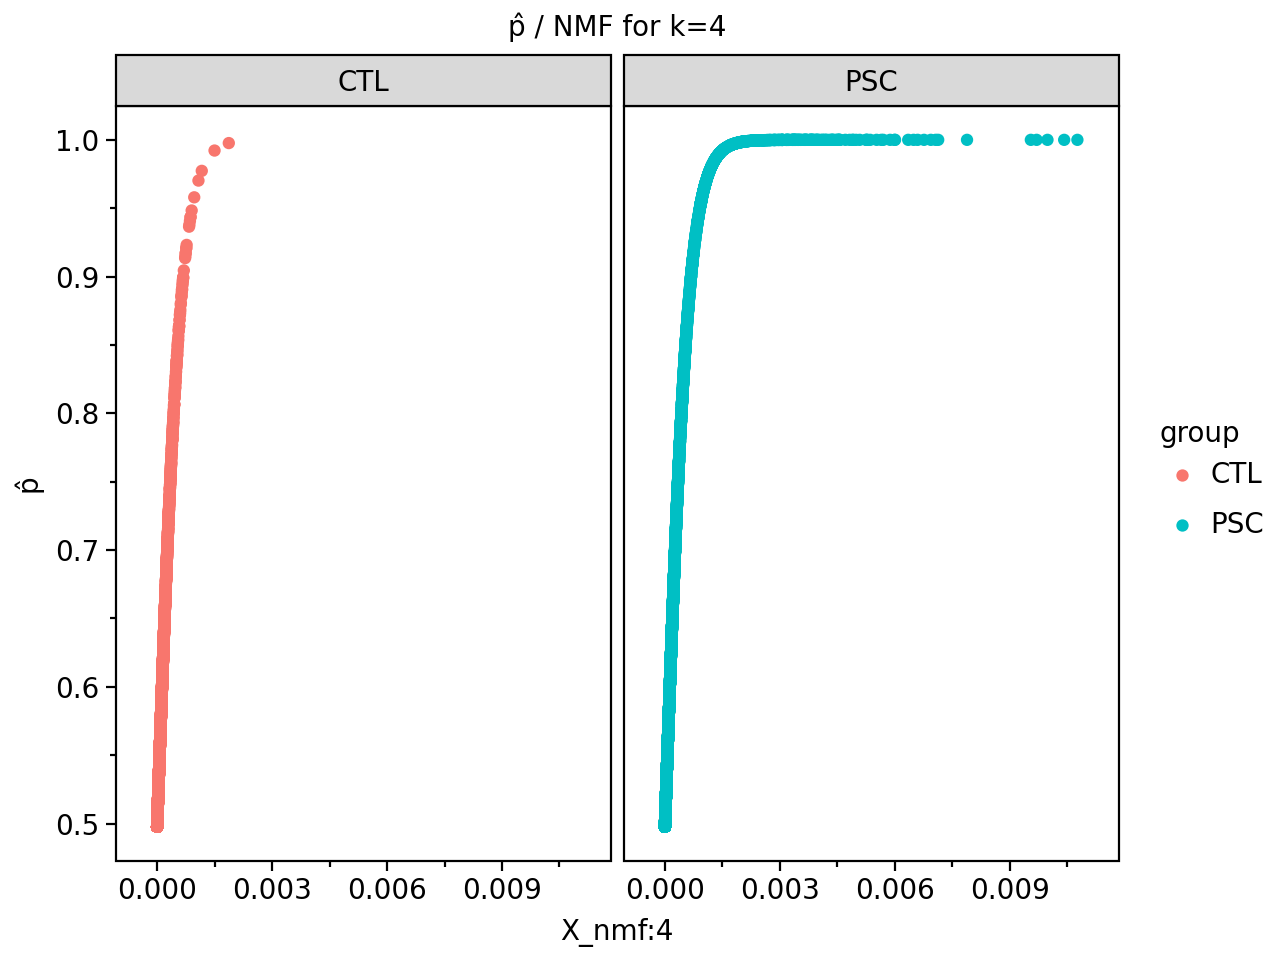

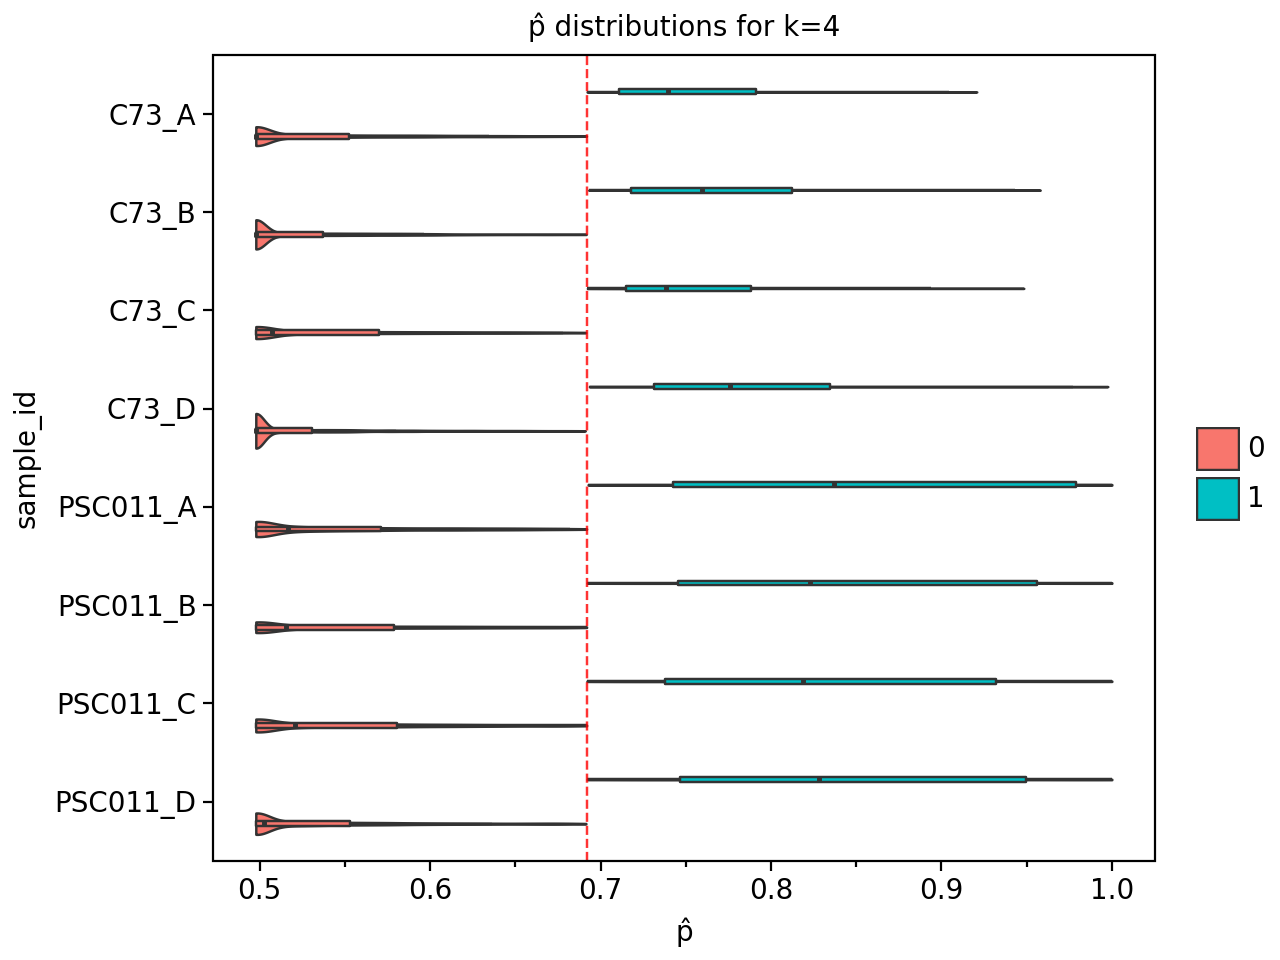

In [7]:
for k in [4]:
    for p in pl_k_sp(psc, k):
        p.show()

we can also see that factor 6 shows a strong control-specific profile \
we plot its (and associated p_hat) distributions below:

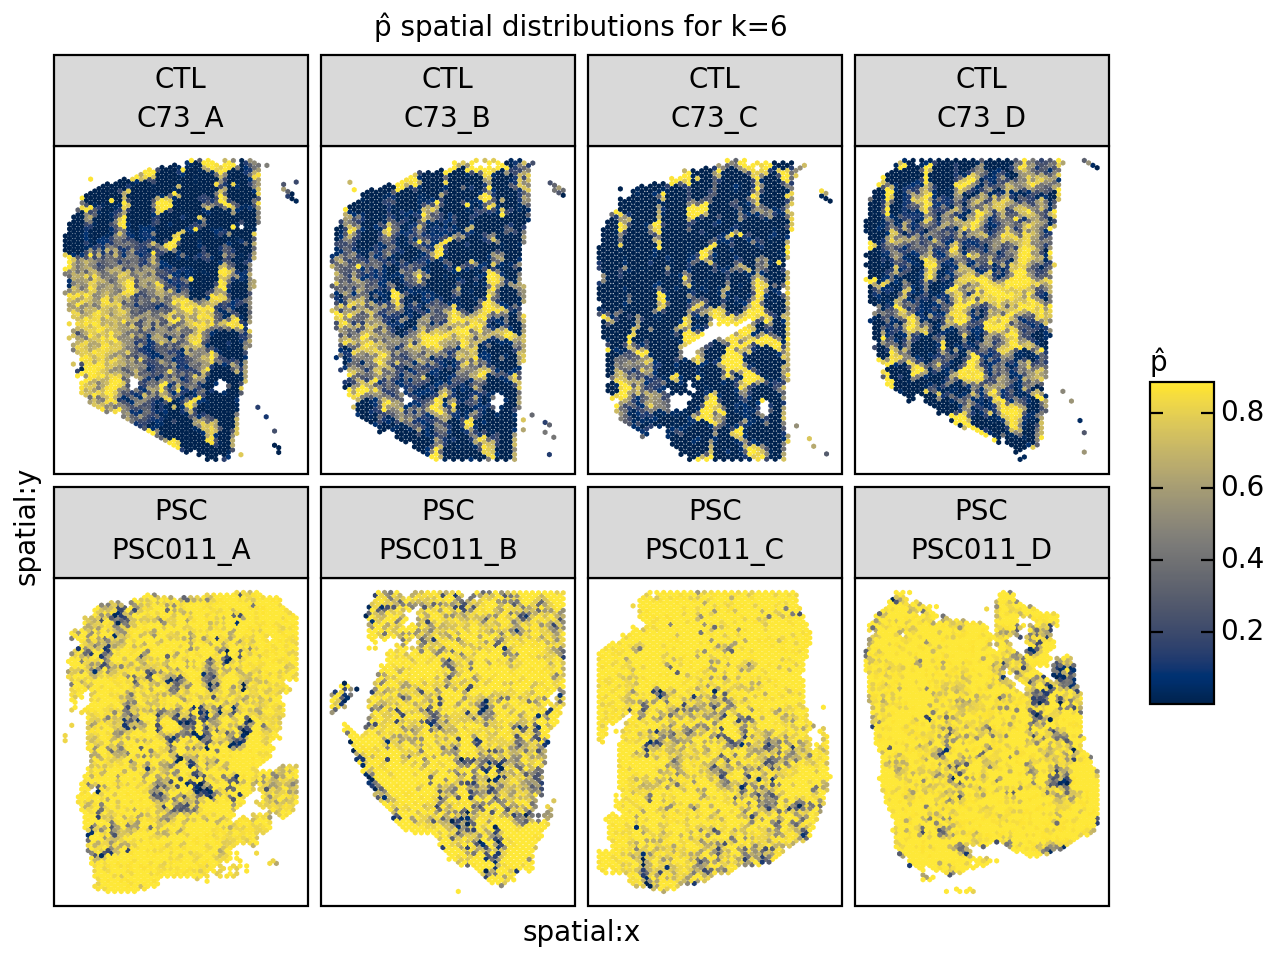

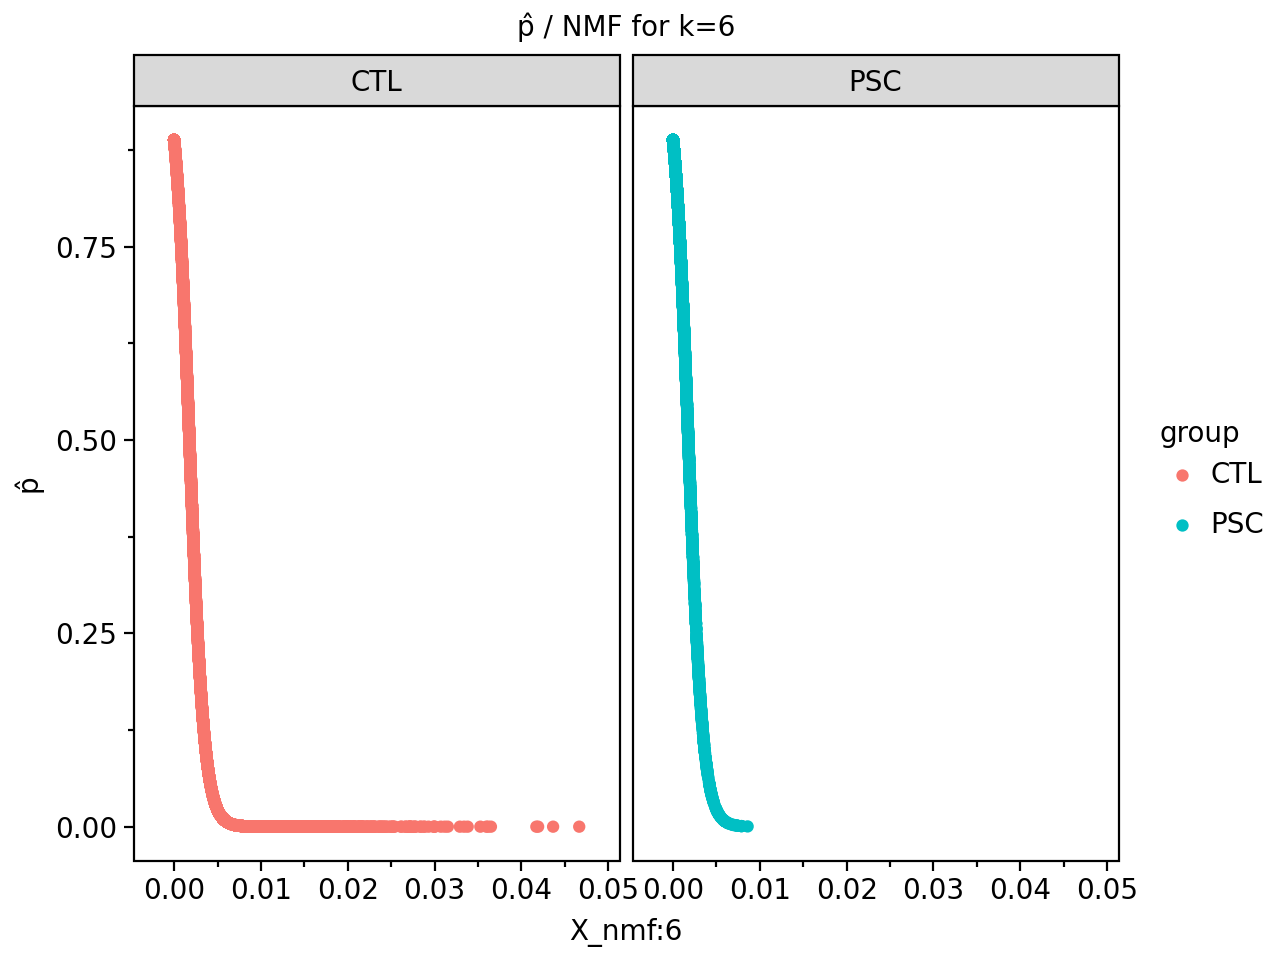

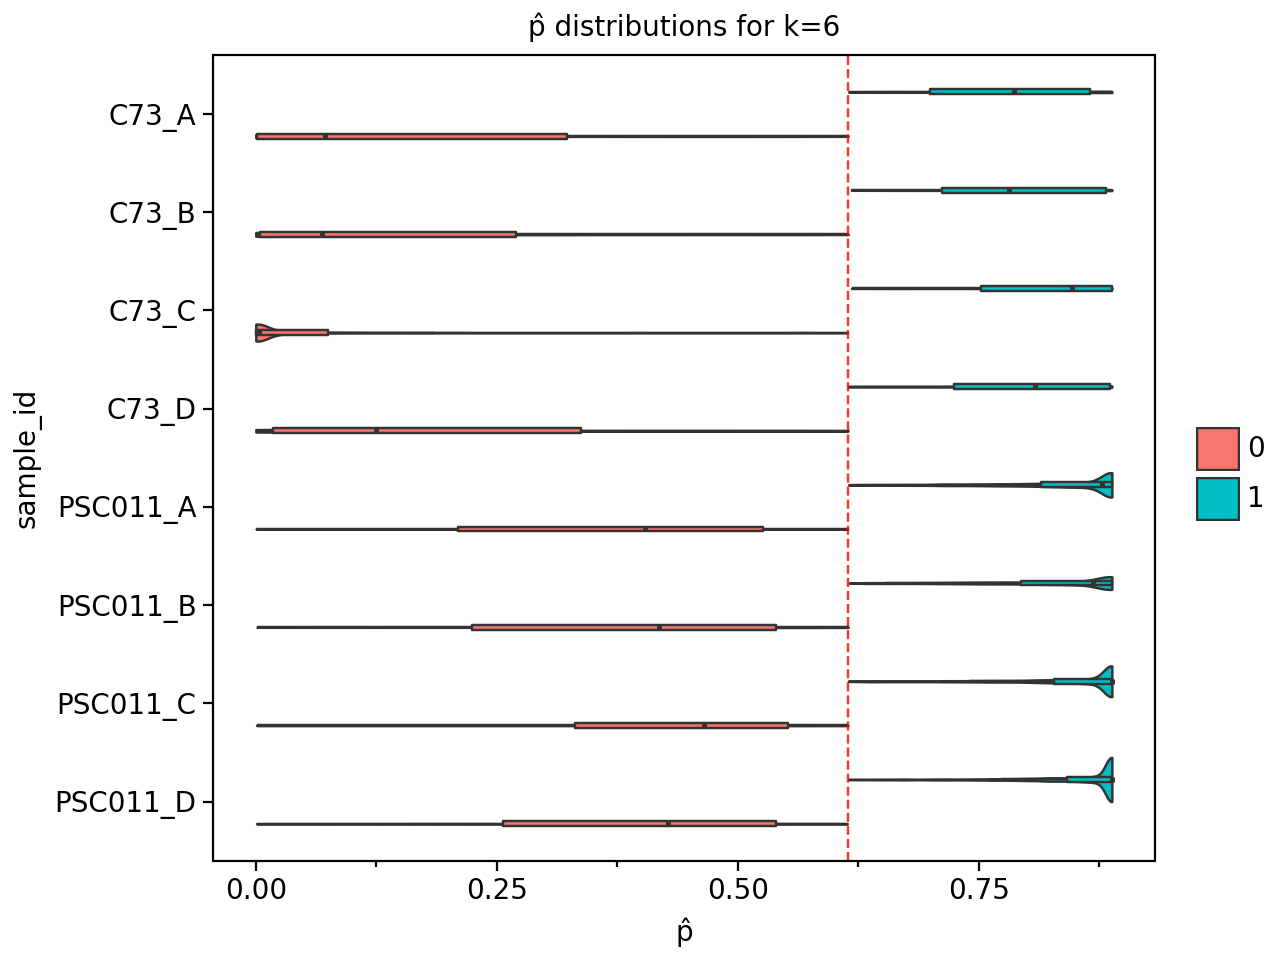

In [8]:
for k in [6]:
    for p in pl_k_sp(psc, k):
        p.show()